## QuantumCircuit class
https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.QuantumCircuit

In [1]:
from qiskit import QuantumCircuit

# Create a new circuit with two qubits
qc = QuantumCircuit(2)

# Add a Hadamard gate to qubit 0
qc.h(0)

# Perform a controlled-X gate on qubit 1, controlled by qubit 0
qc.cx(0, 1)

# Return a text drawing of the circuit.
qc.draw()

┌───┐     
q_0: ┤ H ├──■──
     └───┘┌─┴─┐
q_1: ─────┤ X ├
          └───┘

In [2]:
from qiskit import QuantumCircuit

qc = QuantumCircuit(2, 2)
qc.measure([0], [1])
print(qc.data)

[CircuitInstruction(operation=Instruction(name='measure', num_qubits=1, num_clbits=1, params=[]), qubits=(<Qubit register=(2, "q"), index=0>,), clbits=(<Clbit register=(2, "c"), index=1>,))]


In [3]:
# global phase

from qiskit import QuantumCircuit

circuit = QuantumCircuit(2)
circuit.h(0)
circuit.cx(0, 1)
print(circuit.global_phase)

0.0


In [4]:
from numpy import pi

circuit.global_phase = pi/4
print(circuit.global_phase)

0.7853981633974483


In [5]:
from qiskit import QuantumCircuit

qc = QuantumCircuit(2, 2, name="my_circuit")
print(qc.name)

my_circuit


In [6]:
# metadata

from qiskit import QuantumCircuit

qc = QuantumCircuit(2, 2, metadata={'experiment_type': 'Bell state experiment'})

print(qc.metadata)

{'experiment_type': 'Bell state experiment'}


In [7]:
# clbit

from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit

qr1 = QuantumRegister(2)
qr2 = QuantumRegister(1)
cr1 = ClassicalRegister(2)
cr2 = ClassicalRegister(1)
qc = QuantumCircuit(qr1, qr2, cr1, cr2)

print("List the qubits in this circuit:", qc.qubits)
print("List the classical bits in this circuit:", qc.clbits)

List the qubits in this circuit: [<Qubit register=(2, "q0"), index=0>, <Qubit register=(2, "q0"), index=1>, <Qubit register=(1, "q1"), index=0>]
List the classical bits in this circuit: [<Clbit register=(2, "c0"), index=0>, <Clbit register=(2, "c0"), index=1>, <Clbit register=(1, "c1"), index=0>]


In [16]:
# parameters

from qiskit.circuit import QuantumCircuit, Parameter, ParameterVector
a, b, elephant = Parameter("a"), Parameter("b"), Parameter("elephant")
circuit = QuantumCircuit(1)
circuit.rx(b, 0)
circuit.rz(elephant, 0)
circuit.ry(a, 0)
circuit.parameters  # sorted alphabetically!


ParameterView([Parameter(a), Parameter(b), Parameter(elephant)])

In [19]:
from qiskit.circuit import QuantumCircuit, Parameter
angles = [Parameter("angle_1"), Parameter("angle_2"), Parameter("angle_10")]
circuit = QuantumCircuit(1)
circuit.u(*angles, 0)
circuit.draw()

┌─────────────────────────────┐
q: ┤ U(angle_1,angle_2,angle_10) ├
   └─────────────────────────────┘

In [20]:
circuit.parameters

ParameterView([Parameter(angle_1), Parameter(angle_10), Parameter(angle_2)])

In [23]:
from qiskit.circuit import QuantumCircuit, Parameter, ParameterVector
x = ParameterVector("x", 12)
circuit = QuantumCircuit(1)
for x_i in x:
    circuit.rx(x_i, 0)
circuit.parameters

ParameterView([ParameterVectorElement(x[0]), ParameterVectorElement(x[1]), ParameterVectorElement(x[2]), ParameterVectorElement(x[3]), ParameterVectorElement(x[4]), ParameterVectorElement(x[5]), ParameterVectorElement(x[6]), ParameterVectorElement(x[7]), ParameterVectorElement(x[8]), ParameterVectorElement(x[9]), ParameterVectorElement(x[10]), ParameterVectorElement(x[11])])

In [24]:
# layout

from qiskit import QuantumCircuit
from qiskit.providers.fake_provider import GenericBackendV2
from qiskit.transpiler import generate_preset_pass_manager

# Create circuit to test transpiler on
qc = QuantumCircuit(3, 3)
qc.h(0)
qc.cx(0, 1)
qc.swap(1, 2)
qc.cx(0, 1)

# Add measurements to the circuit
qc.measure([0, 1, 2], [0, 1, 2])

# Specify the QPU to target
backend = GenericBackendV2(3)

# Transpile the circuit
pass_manager = generate_preset_pass_manager(
optimization_level=1, backend=backend
)
transpiled = pass_manager.run(qc)

# Print the layout after transpilation
print(transpiled.layout.routing_permutation())

[0, 1, 2]


In [25]:
from qiskit import QuantumCircuit
from qiskit.providers.fake_provider import GenericBackendV2
from qiskit.transpiler import generate_preset_pass_manager

qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)
qc.measure_all()

# Print the original circuit
print("Original circuit:")
print(qc)

# Transpile the circuit with a specific basis gates list and print the resulting circuit
backend = GenericBackendV2(2, basis_gates=['u1', 'u2', 'u3', 'cx'])
pm = generate_preset_pass_manager(
    optimization_level=1, backend=backend, scheduling_method="alap"
)
transpiled_qc = pm.run(qc)
print("Transpiled circuit with basis gates ['u1', 'u2', 'u3', 'cx']:")
print(transpiled_qc)

# Print the start times of each instruction in the transpiled circuit
print("Start times of instructions in the transpiled circuit:")
for instruction, start_time in zip(transpiled_qc.data, transpiled_qc.op_start_times):
    print(f"{instruction.operation.name}: {start_time}")

Original circuit:
        ┌───┐      ░ ┌─┐   
   q_0: ┤ H ├──■───░─┤M├───
        └───┘┌─┴─┐ ░ └╥┘┌─┐
   q_1: ─────┤ X ├─░──╫─┤M├
             └───┘ ░  ║ └╥┘
meas: 2/══════════════╩══╩═
                      0  1 
Transpiled circuit with basis gates ['u1', 'u2', 'u3', 'cx']:
            ┌─────────┐          ░ ┌────────────────┐┌─┐
q_0 -> 0 ───┤ U2(0,π) ├──────■───░─┤ Delay(251[dt]) ├┤M├
         ┌──┴─────────┴───┐┌─┴─┐ ░ └──────┬─┬───────┘└╥┘
q_1 -> 1 ┤ Delay(241[dt]) ├┤ X ├─░────────┤M├─────────╫─
         └────────────────┘└───┘ ░        └╥┘         ║ 
 meas: 2/══════════════════════════════════╩══════════╩═
                                           1          0 
Start times of instructions in the transpiled circuit:
u2: 0
delay: 0
cx: 241
barrier: 2429
delay: 2429
measure: 2680
measure: 2429


In [26]:
# num_ancillas

from qiskit import QuantumCircuit, QuantumRegister, AncillaRegister

# Create a 2-qubit quantum circuit
reg = QuantumRegister(2)
qc = QuantumCircuit(reg)

# Create an ancilla register with 1 qubit
anc = AncillaRegister(1)
qc.add_register(anc)  # Add the ancilla register to the circuit

print("Number of ancilla qubits:", qc.num_ancillas)

Number of ancilla qubits: 1


In [27]:
# num_clbits

from qiskit import QuantumCircuit

# Create a new circuit with two qubits and one classical bit
qc = QuantumCircuit(2, 1)
print("Number of classical bits:", qc.num_clbits)

Number of classical bits: 1


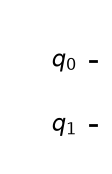

In [30]:
# add_var

from qiskit.circuit import QuantumCircuit

qc = QuantumCircuit(2)
my_var = qc.add_var("my_var", False)
qc.draw("mpl")  # Draw the circuit to visualize the added variable

In [44]:
from qiskit.circuit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit.classical import expr, types

my_var = expr.Var.new("my_var", types.Uint(8))

cr1 = ClassicalRegister(8, "cr1")
cr2 = ClassicalRegister(8, "cr2")
qc = QuantumCircuit(QuantumRegister(8), cr1, cr2)

# Get some measurement results into each register.
qc.h(0)
for i in range(1, 8):
    qc.cx(0, i)
qc.measure(range(8), cr1)

qc.reset(range(8))
qc.h(0)
for i in range(1, 8):
    qc.cx(0, i)
qc.measure(range(8), cr2)

# Now when we add the variable, it is initialized using the real-time state of the
# two classical registers we measured into above.
qc.add_var(my_var, expr.bit_and(cr1, cr2))

Var(UUID('102929d6-8e2b-4ae3-8214-df02e8fda1e4'), Uint(8), name='my_var')

In [45]:
# add_stretch

from qiskit.circuit import QuantumCircuit, Duration
from qiskit.circuit.classical import expr

qc = QuantumCircuit(2)
my_stretch = qc.add_stretch("my_stretch")

qc.delay(expr.add(Duration.dt(200), my_stretch), 1)

In [46]:
# find_bit

from qiskit.circuit import QuantumCircuit, Qubit

qc = QuantumCircuit(3, 3)
qc.h(0)
qc.cx(0, 1)
qc.cx(1, 2)
qc.measure([0, 1, 2], [0, 1, 2])

# The `.qubits` and `.clbits` fields are not integers.
assert isinstance(qc.data[0].qubits[0], Qubit)
# ... but we can use `find_bit` to retrieve them.
assert qc.find_bit(qc.data[0].qubits[0]).index == 0

simple = [
    (
        instruction.operation.name,
        [qc.find_bit(bit).index for bit in instruction.qubits],
        [qc.find_bit(bit).index for bit in instruction.clbits],
    )
    for instruction in qc.data
]

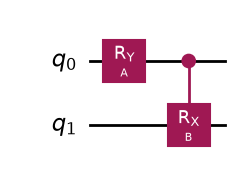

In [48]:
# assign_parameters

from qiskit.circuit import QuantumCircuit, Parameter

circuit = QuantumCircuit(2)
params = [Parameter('A'), Parameter('B'), Parameter('C')]
circuit.ry(params[0], 0)
circuit.crx(params[1], 0, 1)
circuit.draw('mpl')


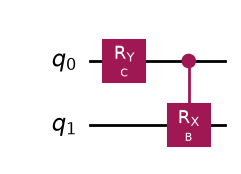

In [49]:
circuit.assign_parameters({params[0]: params[2]}, inplace=True)
circuit.draw('mpl')

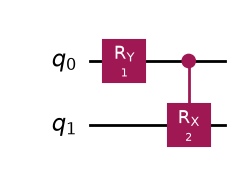

In [51]:
from qiskit.circuit import QuantumCircuit, ParameterVector

circuit = QuantumCircuit(2)
params = ParameterVector('P', 2)
circuit.ry(params[0], 0)
circuit.crx(params[1], 0, 1)

bound_circuit = circuit.assign_parameters([1, 2])
bound_circuit.draw('mpl')


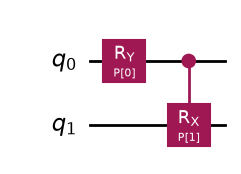

In [52]:
circuit.draw('mpl')

In [58]:
# get_parameter

from qiskit.circuit import QuantumCircuit, Parameter

my_param = Parameter("my_param")

# Create a parametrized circuit.
qc = QuantumCircuit(1)
qc.rx(my_param, 0)

# We can use 'my_param' as a parameter, but let's say we've lost the Python object
# and need to retrieve it.
my_param_again = qc.get_parameter("my_param")

assert my_param == my_param_again

In [59]:
assert qc.get_parameter("my_param", None) == my_param
assert qc.get_parameter("unknown_param", None) is None

In [61]:
# get_var

from qiskit.circuit import QuantumCircuit

# Create a circuit and create a variable in it.
qc = QuantumCircuit()
my_var = qc.add_var("my_var", False)

# We can use 'my_var' as a variable, but let's say we've lost the Python object and
# need to retrieve it.
my_var_again = qc.get_var("my_var")

assert my_var == my_var_again

In [62]:
assert qc.get_var("my_var", None) == my_var
assert qc.get_var("unknown_variable", None) is None

In [63]:
# get_stretch

from qiskit.circuit import QuantumCircuit

# Create a circuit and create a variable in it.
qc = QuantumCircuit()
my_stretch = qc.add_stretch("my_stretch")

# We can use 'my_stretch' as a variable, but let's say we've lost the Python object and
# need to retrieve it.
my_stretch_again = qc.get_stretch("my_stretch")

assert my_stretch == my_stretch_again

In [64]:
assert qc.get_stretch("my_stretch", None) == my_stretch
assert qc.get_stretch("unknown_stretch", None) is None

In [72]:
# compose

# lhs.compose(rhs, qubits=[3, 2], inplace=True)

from qiskit import QuantumCircuit

# Main circuit with 4 qubits
# lhs = QuantumCircuit(4, name="Main Circuit")

# Circuit to be inserted, with 2 qubits
rhs = QuantumCircuit(2, name="Sub Circuit")


# Add operations to rhs
rhs.h(0)
rhs.cx(0, 1)

lhs.compose(rhs, qubits=[3, 2], inplace=True)

print("RHS Circuit:")
print(lhs.draw())

RHS Circuit:
                                   
q_0: ──────────────────────────────
                                   
q_1: ──────────────────────────────
          ┌───┐     ┌───┐     ┌───┐
q_2: ─────┤ X ├─────┤ X ├─────┤ X ├
     ┌───┐└─┬─┘┌───┐└─┬─┘┌───┐└─┬─┘
q_3: ┤ H ├──■──┤ H ├──■──┤ H ├──■──
     └───┘     └───┘     └───┘     


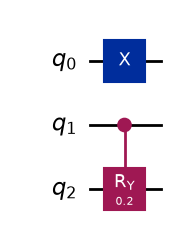

In [ ]:
# tensor

from qiskit import QuantumCircuit
top = QuantumCircuit(1)
top.x(0);
bottom = QuantumCircuit(2)
bottom.cry(0.2, 0, 1);
tensored = bottom.tensor(top)
tensored.draw('mpl')

In [73]:
# initialize

import numpy as np
from qiskit import QuantumCircuit

circuit = QuantumCircuit(1)
circuit.initialize([1/np.sqrt(2), -1/np.sqrt(2)], 0)
circuit.draw()

┌──────────────────────────────┐
q: ┤ Initialize(0.70711,-0.70711) ├
   └──────────────────────────────┘

In [74]:
import numpy as np
from qiskit import QuantumCircuit

circuit = QuantumCircuit(2)
circuit.initialize('01', circuit.qubits)
circuit.draw()

┌──────────────────┐
q_0: ┤0                 ├
     │  Initialize(0,1) │
q_1: ┤1                 ├
     └──────────────────┘

In [75]:
import numpy as np
from qiskit import QuantumCircuit

circuit = QuantumCircuit(2)
circuit.initialize([0, 1/np.sqrt(2), -1.j/np.sqrt(2), 0], circuit.qubits)
circuit.draw()

┌────────────────────────────────────┐
q_0: ┤0                                   ├
     │  Initialize(0,0.70711,-0.70711j,0) │
q_1: ┤1                                   ├
     └────────────────────────────────────┘

In [76]:
# measure

from qiskit import QuantumCircuit
circuit = QuantumCircuit(1, 1)
circuit.h(0)
circuit.measure(0, 0)
circuit.draw()

┌───┐┌─┐
  q: ┤ H ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0

In [77]:
circuit = QuantumCircuit(2, 2)
circuit.measure([0,1], [0,1])

In [78]:
circuit = QuantumCircuit(2, 2)
circuit.measure(0, 0)
circuit.measure(1, 1)

In [79]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
qreg = QuantumRegister(2, "qreg")
creg = ClassicalRegister(2, "creg")
circuit = QuantumCircuit(qreg, creg)
circuit.measure(qreg, creg)

In [80]:
circuit = QuantumCircuit(qreg, creg)
circuit.measure(qreg[0], creg[0])
circuit.measure(qreg[1], creg[1])

In [81]:
# prepare_state

import numpy as np
from qiskit import QuantumCircuit

circuit = QuantumCircuit(1)
circuit.prepare_state([1/np.sqrt(2), -1/np.sqrt(2)], 0)
circuit.draw()

┌─────────────────────────────────────┐
q: ┤ State Preparation(0.70711,-0.70711) ├
   └─────────────────────────────────────┘

In [82]:
import numpy as np
from qiskit import QuantumCircuit

circuit = QuantumCircuit(2)
circuit.prepare_state('01', circuit.qubits)
circuit.draw()

┌─────────────────────────┐
q_0: ┤0                        ├
     │  State Preparation(0,1) │
q_1: ┤1                        ├
     └─────────────────────────┘

In [83]:
import numpy as np
from qiskit import QuantumCircuit

circuit = QuantumCircuit(2)
circuit.prepare_state([0, 1/np.sqrt(2), -1.j/np.sqrt(2), 0], circuit.qubits)
circuit.draw()

┌───────────────────────────────────────────┐
q_0: ┤0                                          ├
     │  State Preparation(0,0.70711,-0.70711j,0) │
q_1: ┤1                                          ├
     └───────────────────────────────────────────┘

In [86]:
# unitary

from qiskit import QuantumCircuit
matrix = [[0, 0, 0, 1],
        [0, 0, 1, 0],
        [1, 0, 0, 0],
        [0, 1, 0, 0]]
circuit = QuantumCircuit(2)
circuit.unitary(matrix, [0, 1])


In [89]:
# box

from qiskit.circuit import QuantumCircuit, Annotation

class MyAnnotation(Annotation):
    namespace = "my.namespace"

qc = QuantumCircuit(9)
with qc.box():
    qc.cz(0, 1)
    qc.cz(2, 3)
with qc.box([MyAnnotation()]):
    qc.cz(4, 5)
    qc.cz(6, 7)
    qc.noop(8)

qc.draw()


┌───────     ───────┐                      
q_0: ┤        ─■─        ├──────────────────────
     │         │         │                      
q_1: ┤        ─■─        ├──────────────────────
     │ Box-0       End-0 │                      
q_2: ┤        ─■─        ├──────────────────────
     │         │         │                      
q_3: ┤        ─■─        ├──────────────────────
     └───────     ───────┘┌───────     ───────┐ 
q_4: ─────────────────────┤        ─■─        ├─
                          │         │         │ 
q_5: ─────────────────────┤        ─■─        ├─
                          │                   │ 
q_6: ─────────────────────┤ Box-0  ─■─  End-0 ├─
                          │         │         │ 
q_7: ─────────────────────┤        ─■─        ├─
                          │                   │ 
q_8: ─────────────────────┤        ───        ├─
                          └───────     ───────┘

In [91]:
from qiskit.circuit import QuantumCircuit, BoxOp

body_0 = QuantumCircuit(4)
body_0.cz(0, 1)
body_0.cz(2, 3)

# Note that the qubit indices inside a body related only to the body.  The
# association with qubits in the containing circuit is made by the ``qubits``
# argument to `QuantumCircuit.box`.
body_1 = QuantumCircuit(5)
body_1.cz(0, 1)
body_1.cz(2, 3)

qc = QuantumCircuit(9)
qc.box(body_0, [0, 1, 2, 3], [])
qc.box(body_1, [4, 5, 6, 7, 8], [])

qc.draw()

┌───────     ───────┐                      
q_0: ┤        ─■─        ├──────────────────────
     │         │         │                      
q_1: ┤        ─■─        ├──────────────────────
     │ Box-0       End-0 │                      
q_2: ┤        ─■─        ├──────────────────────
     │         │         │                      
q_3: ┤        ─■─        ├──────────────────────
     └───────     ───────┘┌───────     ───────┐ 
q_4: ─────────────────────┤        ─■─        ├─
                          │         │         │ 
q_5: ─────────────────────┤        ─■─        ├─
                          │                   │ 
q_6: ─────────────────────┤ Box-0  ─■─  End-0 ├─
                          │         │         │ 
q_7: ─────────────────────┤        ─■─        ├─
                          │                   │ 
q_8: ─────────────────────┤        ───        ├─
                          └───────     ───────┘

In [103]:
# for_loop

from qiskit import QuantumCircuit
qc = QuantumCircuit(2, 1)

with qc.for_loop(range(5)) as i:
    qc.h(0)
    qc.cx(0, 1)
    qc.measure(0, 0)
    with qc.if_test((0, True)):
        qc.break_loop()

qc.draw()

┌─────────────────── ┌───┐     ┌─┐┌────── ┌─────────────┐ ───────┐ »
q_0: ┤                    ┤ H ├──■──┤M├┤       ┤1            ├        ├─»
     │ For-0 range(0, 5)  └───┘┌─┴─┐└╥┘│ If-1  │             │  End-1 │ »
q_1: ┤                    ─────┤ X ├─╫─┤       ┤0 Break_loop ├        ├─»
     └───────────────────      └───┘ ║ └──╥─── │             │ ───────┘ »
  c: ════════════════════════════════╩════■════╡0            ╞══════════»
                                               └─────────────┘          »
«      ───────┐ 
«q_0:         ├─
«       End-0 │ 
«q_1:         ├─
«      ───────┘ 
«  c: ══════════
«

In [105]:
# if_else

from qiskit.circuit import QuantumCircuit, Qubit, Clbit
bits = [Qubit(), Qubit(), Clbit()]
qc = QuantumCircuit(bits)
qc.h(0)
qc.cx(0, 1)
qc.measure(0, 0)
with qc.if_test((bits[2], 0)) as else_:
    qc.h(0)
with else_:
    qc.x(0)

qc.draw()

┌───┐     ┌─┐┌────── ┌───┐┌──────── ┌───┐ ───────┐ 
0: ┤ H ├──■──┤M├┤ If-0  ┤ H ├┤ Else-0  ┤ X ├  End-0 ├─
   └───┘┌─┴─┐└╥┘└──╥─── └───┘└──────── └───┘ ───────┘ 
1: ─────┤ X ├─╫────╫──────────────────────────────────
        └───┘ ║    ║                                  
0: ═══════════╩════o══════════════════════════════════

In [107]:
# if_test

from qiskit.circuit import QuantumCircuit, Qubit, Clbit
bits = [Qubit(), Qubit(), Qubit(), Clbit(), Clbit()]
qc = QuantumCircuit(bits)

qc.h(0)
qc.cx(0, 1)
qc.measure(0, 0)
qc.h(0)
qc.cx(0, 1)
qc.measure(0, 1)

with qc.if_test((bits[3], 0)) as else_:
    qc.x(2)
with else_:
    qc.h(2)
    qc.z(2)

qc.draw()

┌───┐     ┌─┐┌───┐                                                ┌─┐
0: ┤ H ├──■──┤M├┤ H ├─────────────────────────────────────────────■──┤M├
   └───┘┌─┴─┐└╥┘└───┘                                           ┌─┴─┐└╥┘
1: ─────┤ X ├─╫─────────────────────────────────────────────────┤ X ├─╫─
        └───┘ ║      ┌────── ┌───┐┌──────── ┌───┐┌───┐ ───────┐ └───┘ ║ 
2: ───────────╫──────┤ If-0  ┤ X ├┤ Else-0  ┤ H ├┤ Z ├  End-0 ├───────╫─
              ║      └──╥─── └───┘└──────── └───┘└───┘ ───────┘       ║ 
0: ═══════════╩═════════o═════════════════════════════════════════════╬═
                                                                      ║ 
1: ═══════════════════════════════════════════════════════════════════╩═

In [109]:
# switch

from qiskit.circuit import QuantumCircuit, ClassicalRegister, QuantumRegister
qreg = QuantumRegister(3)
creg = ClassicalRegister(3)
qc = QuantumCircuit(qreg, creg)
qc.h([0, 1, 2])
qc.measure([0, 1, 2], [0, 1, 2])

with qc.switch(creg) as case:
    with case(0):
        qc.x(0)
    with case(1, 2):
        qc.z(1)
    with case(case.DEFAULT):
        qc.cx(0, 1)

qc.draw()

┌───┐┌─┐      ┌────────── ┌──────────── ┌───┐┌───────────────      »
q19_0: ┤ H ├┤M├──────┤           ┤             ┤ X ├┤                ─────»
       ├───┤└╥┘┌─┐   │ Switch-0  │ Case-0 (0)  └───┘│ Case-0 (1, 2)  ┌───┐»
q19_1: ┤ H ├─╫─┤M├───┤           ┤             ─────┤                ┤ Z ├»
       ├───┤ ║ └╥┘┌─┐└────╥───── └────────────      └─────────────── └───┘»
q19_2: ┤ H ├─╫──╫─┤M├─────╫───────────────────────────────────────────────»
       └───┘ ║  ║ └╥┘  ┌──╨──┐                                            »
 c3: 3/══════╩══╩══╩═══╡ 0x7 ╞════════════════════════════════════════════»
             0  1  2   └─────┘                                            »
«       ┌────────────────       ───────┐ 
«q19_0: ┤                 ──■──        ├─
«       │ Case-0 default  ┌─┴─┐  End-0 │ 
«q19_1: ┤                 ┤ X ├        ├─
«       └──────────────── └───┘ ───────┘ 
«q19_2: ─────────────────────────────────
«                                        
« c3: 3/═════════════════════════════════
«

In [118]:
# while_loop

from qiskit.circuit import QuantumCircuit, Clbit, Qubit
bits = [Qubit(), Qubit(), Clbit()]
qc = QuantumCircuit(bits)

with qc.while_loop((bits[2], 0)):
    qc.h(0)
    qc.cx(0, 1)
    qc.measure(0, 0)

qc.draw()

┌───────── ┌───┐     ┌─┐ ───────┐ 
0: ┤          ┤ H ├──■──┤M├        ├─
   │ While-0  └───┘┌─┴─┐└╥┘  End-0 │ 
1: ┤          ─────┤ X ├─╫─        ├─
   └────╥────      └───┘ ║  ───────┘ 
0: ═════o════════════════╩═══════════

In [120]:
# noop

from qiskit.circuit import QuantumCircuit

qc = QuantumCircuit(3)
with qc.box():
    # This control-flow block will only use qubits 0 and 1.
    qc.cx(0, 1)
with qc.box():
    # This control-flow block will contain only the same operation as the previous
    # block, but it will also mark qubit 2 as "used" by the box.
    qc.cx(0, 1)
    qc.noop(2)

qc.draw()

┌───────       ───────┐ ┌───────       ───────┐ 
q_0: ┤        ──■──        ├─┤        ──■──        ├─
     │ Box-0  ┌─┴─┐  End-0 │ │        ┌─┴─┐        │ 
q_1: ┤        ┤ X ├        ├─┤ Box-0  ┤ X ├  End-0 ├─
     └─────── └───┘ ───────┘ │        └───┘        │ 
q_2: ────────────────────────┤        ─────        ├─
                             └───────       ───────┘

In [122]:
# remove_final_measurements

from qiskit.circuit import QuantumCircuit
from qiskit.transpiler.passes import RemoveFinalMeasurements

qc = QuantumCircuit(2, 2)
qc.h(0)
qc.cx(0, 1)
qc.barrier()
qc.measure([0, 1], [0, 1])

pass_ = RemoveFinalMeasurements()
just_bell = pass_(qc)

qc.draw()   

┌───┐      ░ ┌─┐   
q_0: ┤ H ├──■───░─┤M├───
     └───┘┌─┴─┐ ░ └╥┘┌─┐
q_1: ─────┤ X ├─░──╫─┤M├
          └───┘ ░  ║ └╥┘
c: 2/══════════════╩══╩═
                   0  1

## Circuit properties

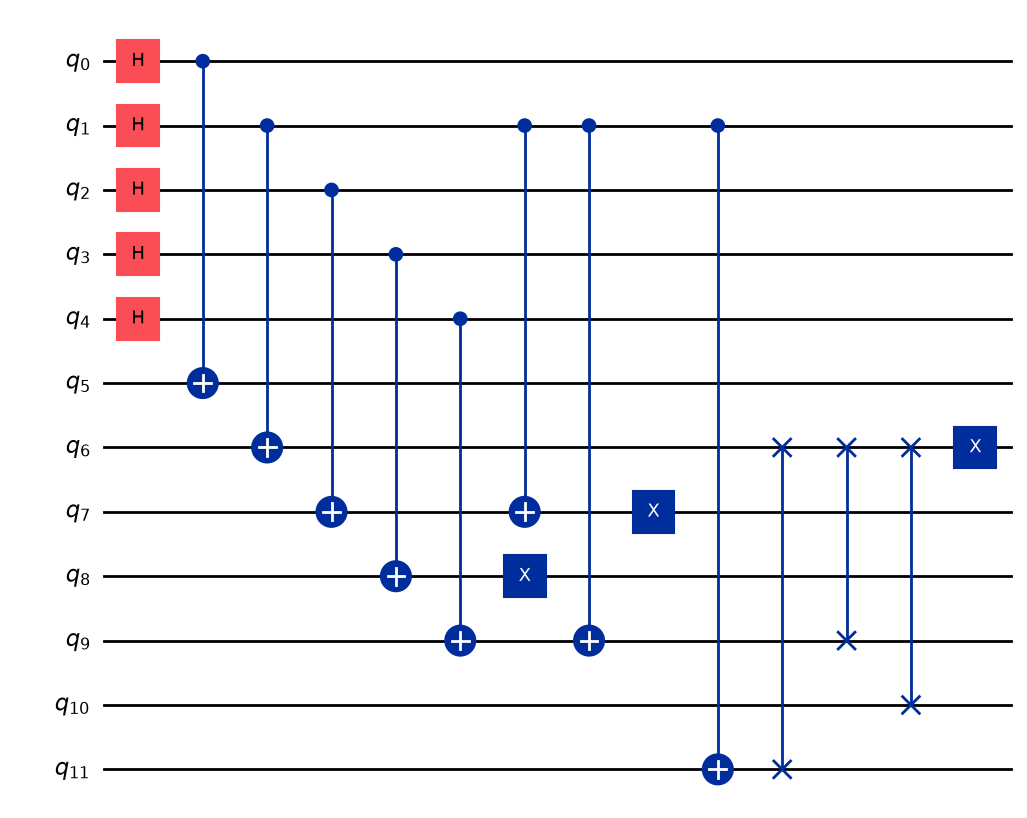

In [123]:
# Simple circuit metrics

from qiskit import QuantumCircuit
qc = QuantumCircuit(12)
for idx in range(5):
   qc.h(idx)
   qc.cx(idx, idx+5)

qc.cx(1, 7)
qc.x(8)
qc.cx(1, 9)
qc.x(7)
qc.cx(1, 11)
qc.swap(6, 11)
qc.swap(6, 9)
qc.swap(6, 10)
qc.x(6)
qc.draw('mpl')

In [124]:
assert qc.width() == 12

In [125]:
assert qc.num_qubits == 12

In [126]:
qc.count_ops()

OrderedDict([('cx', 8), ('h', 5), ('x', 3), ('swap', 3)])

In [127]:
assert qc.size() == 19

In [128]:
# depth

from qiskit.circuit import QuantumCircuit
qc = QuantumCircuit(4)
qc.h(0)
qc.cx(0, 1)
qc.h(2)
qc.cx(2, 3)
assert qc.depth() == 2

In [129]:
assert qc.depth(lambda instr: len(instr.qubits) > 1) == 1

## Visualization

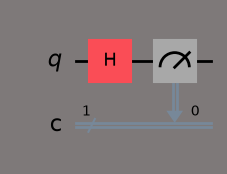

In [135]:
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit
qc = QuantumCircuit(1, 1)
qc.h(0)
qc.measure(0, 0)
qc.draw(output='mpl', style={'backgroundcolor': "#7E7979"})